# Operational Analysis — Laboratory Turnaround Time (TAT)

**Question this notebook answers:** how fast does the laboratory turn samples around, where
is time lost in the workflow, which departments / tests / analyzers are slow, and where do
samples get rejected?

**Data:** three already-merged datasets in `dataset/cleaned/`:
`item_analysis.csv` (one row per test order), `report_analysis.csv` (one row per reported
parameter) and `sample_state_analysis.csv` (one row per sample status change: collected →
received → processing → verified / reported / rejected).

**Contents:** setup & data load · validation (§3) · dates in UTC (§4) · TAT fields & calculation (§5–7)
· clean TAT table (§8) · stage analysis (§9) · processing & rejections (§10) ·
analyzer capacity (§11) · report PDF (§12).

## 1. Setup

Libraries, folder paths and one reusable list of the three data files. The cleaned
datasets are read only — never written back.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 40)

# --- Reusable paths (notebook lives in notebook/, data in ../dataset/cleaned/) ---
NOTEBOOK_DIR = Path.cwd()
PROJECT_DIR = NOTEBOOK_DIR.parent
DATA_DIR = PROJECT_DIR / "dataset" / "cleaned"

CLEANED_DATASETS = {
    "item_analysis": DATA_DIR / "item_analysis.csv",
    "report_analysis": DATA_DIR / "report_analysis.csv",
    "sample_state_analysis": DATA_DIR / "sample_state_analysis.csv",
}

In [2]:
def load_dataset(name: str, path: Path) -> pd.DataFrame:
    """Load one cleaned CSV dataset. utf-8-sig strips the BOM written by the cleaning step."""
    df = pd.read_csv(path, encoding="utf-8-sig")
    print(f"Loaded   : {name}  <-  {path.name}")
    print(f"  path   : {path}")
    print(f"  shape  : {df.shape[0]:,} rows x {df.shape[1]} columns\n")
    return df

datasets = {name: load_dataset(name, path) for name, path in CLEANED_DATASETS.items()}

item_df = datasets["item_analysis"]
report_df = datasets["report_analysis"]
sample_state_df = datasets["sample_state_analysis"]

print("Summary")
for name, df in datasets.items():
    print(f"  {name:<22} rows={df.shape[0]:>7,}  cols={df.shape[1]}")

Loaded   : item_analysis  <-  item_analysis.csv
  path   : C:\Users\yusra\Documents\Python\UV\laboratory-data-analysis\src\laboratory_data_analysis\dataset\cleaned\item_analysis.csv
  shape  : 72,947 rows x 32 columns



Loaded   : report_analysis  <-  report_analysis.csv
  path   : C:\Users\yusra\Documents\Python\UV\laboratory-data-analysis\src\laboratory_data_analysis\dataset\cleaned\report_analysis.csv
  shape  : 125,981 rows x 43 columns



Loaded   : sample_state_analysis  <-  sample_state_analysis.csv
  path   : C:\Users\yusra\Documents\Python\UV\laboratory-data-analysis\src\laboratory_data_analysis\dataset\cleaned\sample_state_analysis.csv
  shape  : 235,558 rows x 19 columns

Summary
  item_analysis          rows= 72,947  cols=32
  report_analysis        rows=125,981  cols=43
  sample_state_analysis  rows=235,558  cols=19


## 3. Validation — are all needed columns present?

Checks that each dataset has every column the analysis needs (keys, timestamps, context
fields). If anything is missing, the notebook stops and the problem goes back to the
cleaning step.

In [3]:
REQUIRED_FIELDS = {
    "item_analysis": [
        # keys
        "order_item_id", "order_id", "test_id", "sample_id",
        # context for operational breakdowns
        "department_name", "test_name", "priority", "sample_type",
        # SLA reference
        "normal_tat_h",
        # workflow / quality flags
        "order_created_at", "is_rejected",
    ],
    "report_analysis": [
        # keys
        "report_id", "order_item_id", "parameter_id", "sample_id",
        # report workflow
        "dispatched_at", "order_created_at",
        # result context
        "parameter_name", "value", "unit_x", "flag",
    ],
    "sample_state_analysis": [
        # state log (long format)
        "sample_state_id", "sample_id", "state", "timestamp",
        # linkage + context
        "order_id", "patient_id", "order_created_at", "sample_type", "is_rejected",
    ],
}


def validate_required_fields(name: str, df: pd.DataFrame, required: list[str]) -> bool:
    """Check a dataset for all required fields. Returns True when the contract is satisfied."""
    missing = [c for c in required if c not in df.columns]
    if missing:
        print(f"{name:<24} MISSING: {missing}")
        return False
    print(f"{name:<24} OK  ({len(required)}/{len(required)} required fields present)")
    return True


validation_ok = all(
    validate_required_fields(name, datasets[name], fields)
    for name, fields in REQUIRED_FIELDS.items()
)
assert validation_ok, "Required fields missing -> re-visit the cleaning/merging pipeline."
print("\nAll datasets contain the fields required for operational analysis.")

item_analysis            OK  (11/11 required fields present)
report_analysis          OK  (10/10 required fields present)
sample_state_analysis    OK  (9/9 required fields present)

All datasets contain the fields required for operational analysis.


## 4. Dates — real datetimes in UTC

CSV stores timestamps as plain text (e.g. `2025-06-17 23:22:01+00:00`). Before computing
anything, each timestamp column is turned into a true datetime:

- **Already a UTC-aware datetime** → kept as it is (no unnecessary change).
- **Plain text or wrong type** → converted once to UTC with `pd.to_datetime(..., utc=True)`.

All analysis in this project uses UTC, consistently.

In [4]:
# Datetime columns relevant to the operational analysis, per dataset.
DATETIME_COLUMNS = {
    "item_analysis": ["order_created_at"],
    "report_analysis": ["order_created_at", "dispatched_at"],
    "sample_state_analysis": ["timestamp", "order_created_at"],
}


def ensure_utc_datetime(df: pd.DataFrame, columns: list[str], name: str) -> pd.DataFrame:
    """Return a copy of `df` where every column in `columns` is timezone-aware UTC.

    Columns that already carry a tz-aware UTC dtype are preserved as-is; everything
    else (strings/objects/naive) is converted once via pd.to_datetime(..., utc=True).
    Invalid/missing values become NaT instead of raising.
    """
    out = df.copy()
    for col in columns:
        dtype = out[col].dtype
        if isinstance(dtype, pd.DatetimeTZDtype):
            if str(dtype.tz) == "UTC":
                action = "preserved (already tz-aware UTC)"
            else:  # tz-aware but not UTC -> localise correctly to UTC
                out[col] = out[col].dt.tz_convert("UTC")
                action = "tz_convert('UTC')"
        else:
            out[col] = pd.to_datetime(out[col], utc=True, errors="coerce")
            action = "converted from object -> to_datetime(utc=True)"
        print(f"  {name:<22} {col:<18} before={str(dtype):<22} after={out[col].dtype}  [{action}]")
    return out


for name, columns in DATETIME_COLUMNS.items():
    datasets[name] = ensure_utc_datetime(datasets[name], columns, name)

item_df = datasets["item_analysis"]
report_df = datasets["report_analysis"]
sample_state_df = datasets["sample_state_analysis"]

print("\nAudit: first raw string vs stored datetime value")
print(f"  sample_state timestamp : {sample_state_df['timestamp'].iloc[0]}  (dtype {sample_state_df['timestamp'].dtype})")
print(f"  report dispatched_at   : {report_df['dispatched_at'].iloc[0]}  (dtype {report_df['dispatched_at'].dtype})")

  item_analysis          order_created_at   before=str                    after=datetime64[us, UTC]  [converted from object -> to_datetime(utc=True)]


  report_analysis        order_created_at   before=str                    after=datetime64[us, UTC]  [converted from object -> to_datetime(utc=True)]


  report_analysis        dispatched_at      before=str                    after=datetime64[us, UTC]  [converted from object -> to_datetime(utc=True)]


  sample_state_analysis  timestamp          before=str                    after=datetime64[us, UTC]  [converted from object -> to_datetime(utc=True)]
  sample_state_analysis  order_created_at   before=str                    after=datetime64[us, UTC]  [converted from object -> to_datetime(utc=True)]



Audit: first raw string vs stored datetime value
  sample_state timestamp : 2025-06-17 23:54:17+00:00  (dtype datetime64[us, UTC])
  report dispatched_at   : 2025-06-18 07:10:29+00:00  (dtype datetime64[us, UTC])


## 5. TAT fields — the laboratory workflow timeline

*Which timestamps make up the workflow?*

The state log (`sample_state_analysis`) has one row per status change of a sample — its
stages are listed below. Together with `order_created_at` (the test was ordered) and
`dispatched_at` (the report was sent) they form the complete TAT chain:

In [5]:
state_counts = sample_state_df["state"].value_counts()
display(state_counts.to_frame("events"))

print("Distinct workflow stages (in workflow order):")
for stage in ["collected", "received", "processing", "verified", "reported", "rejected"]:
    n = state_counts.get(stage, 0)
    print(f"  {stage:<11} {n:>7,} events")

,events
state,
collected,49260
received,48873
processing,48873
verified,45655
reported,42510
rejected,387


Distinct workflow stages (in workflow order):
  collected    49,260 events
  received     48,873 events
  processing   48,873 events
  verified     45,655 events
  reported     42,510 events
  rejected        387 events


### Workflow timestamp map

**Stages of a sample in the lab**

| Stage | Timestamp | Where it comes from | Meaning |
|---|---|---|---|
| Order placed | `order_created_at` | all three datasets | clinician ordered the test |
| **Sample collection** | `state == 'collected'` | sample_state_analysis | sample drawn from the patient |
| **Sample received** | `state == 'received'` | sample_state_analysis | reception logged the sample |
| Processing start | `state == 'processing'` | sample_state_analysis | sample entered the bench |
| **Verified** | `state == 'verified'` | sample_state_analysis | result checked in the lab |
| **Final report** | `state == 'reported'` | sample_state_analysis | report released |
| Report sent out | `dispatched_at` | report_analysis | parameter-level report dispatch |

**TAT definitions used in this notebook — all in hours**

| Measure | From → To | Everyday meaning |
|---|---|---|
| Pre-analytical TAT | collected → received | getting the sample from ward to lab |
| Analytical TAT | received → verified | actual testing at the bench |
| Post-analytical TAT | verified → reported | checking and releasing the result |
| **Overall TAT (the headline number)** | **collected → final report** | what the patient experiences |

Only samples that actually reach *reported* get a TAT — rejected samples never do.

## 6. One row per sample — the TAT working table

Reshapes the state log so that **each sample** gets one column per stage timestamp, then
adds context: department, priority, sample type, rejection flag — and the sample's target
time (the strictest `normal_tat_h` among its tests).

*`normal_tat_h` is assumed to mean "hours a test should take"; worth checking against lab
policy before trusting SLA conclusions.*

In [6]:
def build_sample_tat(item_df: pd.DataFrame, sample_state_df: pd.DataFrame) -> pd.DataFrame:
    """Pivot the sample state log to one row per sample and attach item context.

    Returns a frame keyed by sample_id with:
      - one datetime column per workflow state (collected/received/processing/verified/reported)
      - context: department_name, priority, sample_type, is_rejected
      - sla_target_h: strictest normal_tat_h among all tests on the sample
    """
    stage_times = sample_state_df.pivot_table(
        index="sample_id", columns="state", values="timestamp", aggfunc="first"
    )
    stage_times.columns = [f"{col}_at" for col in stage_times.columns]

    # One attributes row per sample: first occurrence of shared attributes,
    # min() for the SLA target so the strictest test standard applies.
    attrs = (
        item_df.sort_values("order_item_id")
        .groupby("sample_id")
        .agg(
            department_name=("department_name", "first"),
            priority=("priority", "first"),
            sample_type=("sample_type", "first"),
            is_rejected=("is_rejected", "max"),          # any test rejected -> sample-level flag
            n_tests_on_sample=("order_item_id", "count"),
            sla_target_h=("normal_tat_h", "min"),
        )
    )
    sample_tat = attrs.join(stage_times, how="left")
    return sample_tat.reset_index()


sample_tat = build_sample_tat(item_df, sample_state_df)

print(f"sample_tat: {sample_tat.shape[0]:,} samples x {sample_tat.shape[1]} columns\n")
print("Workflow completeness per stage:")
for col in ["collected_at", "received_at", "processing_at", "verified_at", "reported_at"]:
    n = sample_tat[col].notna().sum()
    print(f"  {col:<16} {n:>7,} ({n / len(sample_tat):>6.1%})")
print(f"  rejected samples : {sample_tat['is_rejected'].sum():>7,}")

sample_tat: 49,260 samples x 13 columns

Workflow completeness per stage:
  collected_at      49,260 (100.0%)
  received_at       48,873 ( 99.2%)
  processing_at     48,873 ( 99.2%)
  verified_at       45,655 ( 92.7%)
  reported_at       42,510 ( 86.3%)
  rejected samples :     387


## 7. TAT in hours — stages and overall

- Computes every stage duration and **overall TAT = collection → final report**, in hours.
- Rejected samples never reach a report → they don't get a TAT and drop out of these
  figures automatically.

In [7]:
def add_tat_columns(df: pd.DataFrame) -> pd.DataFrame:
    """Add TAT intervals, in hours, derived from the workflow timestamps."""
    out = df.copy()
    hours = lambda start, end: (out[end] - out[start]).dt.total_seconds() / 3600

    out["pre_analytical_tat_h"] = hours("collected_at", "received_at")     # collection -> reception
    out["analytical_tat_h"] = hours("received_at", "verified_at")          # reception  -> verification
    out["post_analytical_tat_h"] = hours("verified_at", "reported_at")     # verification -> release
    out["tat_total_h"] = hours("collected_at", "reported_at")              # PRIMARY: collection -> final report

    # Data quality: negative intervals are logically impossible -> invalidate, do not reuse.
    interval_cols = ["pre_analytical_tat_h", "analytical_tat_h", "post_analytical_tat_h", "tat_total_h"]
    for col in interval_cols:
        bad = (out[col] < 0).sum()
        if bad:
            print(f"  invalid: {bad:,} negative values in {col} -> set to NaN")
        out.loc[out[col] < 0, col] = np.nan

    # SLA compliance against the strictest applicable normal TAT.
    in_scope = out["tat_total_h"].notna()
    out["sla_breach"] = np.where(in_scope, out["tat_total_h"] > out["sla_target_h"], np.nan)
    return out


sample_tat = add_tat_columns(sample_tat)

scope = sample_tat["tat_total_h"].notna().sum()
print(f"Samples with primary TAT (collected -> reported): {scope:,} / {len(sample_tat):,} "
      f"({scope / len(sample_tat):.1%} of all samples)")
print(f"Excluded: rejected/no-report samples = {len(sample_tat) - scope:,}, "
      f"SLA breaches flagged on {int(sample_tat['sla_breach'].sum()):,} in-scope samples")

Samples with primary TAT (collected -> reported): 42,510 / 49,260 (86.3% of all samples)
Excluded: rejected/no-report samples = 6,750, SLA breaches flagged on 41,717 in-scope samples


## 8. The final TAT table

One clean row per sample: ID, context (department, priority, sample type), UTC timestamps,
TAT figures, and whether the target was met. This table (`tat_analysis_df`) feeds every
analysis from here on.

In [8]:
FINAL_COLUMNS = [
    # identity
    "sample_id",
    # context
    "department_name", "priority", "sample_type", "n_tests_on_sample", "is_rejected",
    # SLA reference
    "sla_target_h",
    # workflow timestamps (UTC)
    "collected_at", "received_at", "processing_at", "verified_at", "reported_at",
    # TAT intervals, hours
    "pre_analytical_tat_h", "analytical_tat_h", "post_analytical_tat_h", "tat_total_h",
    # outcome flag
    "sla_breach",
]

tat_analysis_df = (
    sample_tat.loc[:, FINAL_COLUMNS]
    .sort_values("sample_id")
    .reset_index(drop=True)
)

display(tat_analysis_df.head())
print(f"\ntat_analysis_df: {tat_analysis_df.shape[0]:,} rows x {tat_analysis_df.shape[1]} columns")

,sample_id,department_name,priority,sample_type,n_tests_on_sample,is_rejected,sla_target_h,collected_at,received_at,processing_at,verified_at,reported_at,pre_analytical_tat_h,analytical_tat_h,post_analytical_tat_h,tat_total_h,sla_breach
0,1,Immunology,stat,serum,3,False,3,2025-06-17 23:54:17+00:00,2025-06-18 02:07:03+00:00,2025-06-18 03:45:54+00:00,2025-06-18 05:37:48+00:00,2025-06-18 07:10:29+00:00,2.21,3.51,1.54,7.27,1.00
1,2,Molecular Diagnostics,routine,blood,1,False,6,2025-06-18 00:21:11+00:00,2025-06-18 07:02:38+00:00,2025-06-18 08:14:07+00:00,2025-06-18 19:07:38+00:00,2025-06-18 19:42:09+00:00,6.69,12.08,0.58,19.35,1.00
2,3,Molecular Diagnostics,routine,blood,3,False,2,2025-07-06 12:06:59+00:00,2025-07-06 18:34:04+00:00,2025-07-06 20:47:50+00:00,2025-07-07 07:03:46+00:00,2025-07-07 08:54:34+00:00,6.45,12.49,1.85,20.79,1.00
3,4,Immunology,routine,serum,2,False,2,2025-07-06 12:32:30+00:00,2025-07-06 18:43:06+00:00,2025-07-06 22:28:25+00:00,NaT,NaT,6.18,NaN,NaN,NaN,NaN
4,5,Histopathology,routine,pleural fluid,2,False,6,2025-02-17 10:41:04+00:00,2025-02-17 12:33:39+00:00,2025-02-17 16:02:26+00:00,2025-02-17 23:51:14+00:00,2025-02-18 01:33:43+00:00,1.88,11.29,1.71,14.88,1.00



tat_analysis_df: 49,260 rows x 17 columns


### First read of the numbers

Overall TAT by priority (stat / routine / emergency) — the lab's usual way of looking at
the work.

In [9]:
in_scope = tat_analysis_df[tat_analysis_df["tat_total_h"].notna()]

overview = (
    in_scope.groupby("priority")["tat_total_h"]
    .agg(samples="count", median_h="median", mean_h="mean", p90_h=lambda s: s.quantile(0.9))
    .assign(breach_rate=lambda t: (
        in_scope.groupby("priority")["sla_breach"].mean().reindex(t.index)))
)
display(overview)

overall_stage = in_scope[["pre_analytical_tat_h", "analytical_tat_h",
                          "post_analytical_tat_h", "tat_total_h"]].median()
print("\nMedian hours per workflow stage (all priorities):")
for name, value in overall_stage.items():
    print(f"  {name:<20} {value:>6.2f}")


,samples,median_h,mean_h,p90_h,breach_rate
priority,,,,,
emergency,6056,15.49,15.51,20.84,0.98
routine,32102,15.53,15.52,20.87,0.98
stat,4352,15.55,15.54,20.89,0.99



Median hours per workflow stage (all priorities):


  pre_analytical_tat_h   4.50
  analytical_tat_h       8.79
  post_analytical_tat_h   2.24
  tat_total_h           15.53


## 9. Stage analysis — where is the time spent?

**Purpose:** break overall TAT into the four workflow stages
(`Collection → Received → Processing → Verified → Reported`) and find the main contributor.

**Questions:** overall, which stage dominates? Which department is slowest? Which stage is
each department's bottleneck?


In [10]:
STAGE_TRANSITIONS = [
    # (column, start timestamp, end timestamp, transition label, short label)
    ("pre_analytical_tat_h",      "collected_at",   "received_at",   "Collection → Received",  "COLL → REC"),
    ("received_processing_tat_h", "received_at",    "processing_at", "Received → Processing",  "REC → PROC"),
    ("processing_verified_tat_h", "processing_at",  "verified_at",   "Processing → Verified",  "PROC → VER"),
    ("post_analytical_tat_h",     "verified_at",    "reported_at",   "Verified → Reported",    "VER → REP"),
    ("tat_total_h",               "collected_at",   "reported_at",   "Collection → Reported",  "Overall TAT"),
]
LAYER_TRANSITIONS = STAGE_TRANSITIONS[:-1]            # the four building blocks of overall TAT
TRANSITION_LABELS = {t[0]: t[3] for t in LAYER_TRANSITIONS}
SHORT_LABELS = {t[0]: t[4] for t in LAYER_TRANSITIONS}
layer_cols = [t[0] for t in LAYER_TRANSITIONS]


def add_stage_transitions(tat_df: pd.DataFrame) -> pd.DataFrame:
    """Extend the existing TAT dataframe with the workflow stage intervals still missing (hours).

    Sections 7-8 already produced pre/analytical/post/total intervals; only transitions
    not present are derived here, and negative results are invalidated to NaN.
    """
    out = tat_df.copy()
    for col, start, end, _, _ in STAGE_TRANSITIONS:
        if col not in out.columns:
            hours = (out[end] - out[start]).dt.total_seconds() / 3600
            out[col] = hours.where(hours >= 0)   # logically impossible intervals -> NaN
    return out


stage_analysis_df = add_stage_transitions(tat_analysis_df)

print("Stage intervals available (hours):\n")
for col, start, end, label, short in STAGE_TRANSITIONS:
    n = int(stage_analysis_df[col].notna().sum())
    print(f"  {label:<24} ({short:<10}) valid pairs: {n:>7,}  ({n / len(stage_analysis_df):>6.1%})")

Stage intervals available (hours):



  Collection → Received    (COLL → REC) valid pairs:  48,873  ( 99.2%)
  Received → Processing    (REC → PROC) valid pairs:  48,873  ( 99.2%)
  Processing → Verified    (PROC → VER) valid pairs:  45,655  ( 92.7%)
  Verified → Reported      (VER → REP ) valid pairs:  42,510  ( 86.3%)
  Collection → Reported    (Overall TAT) valid pairs:  42,510  ( 86.3%)


### 9.1 Stage times, overall

Hours per transition (median and mean), and — for samples that completed **all four
stages** — each stage's **share of overall TAT**. Shares are taken from complete samples on
purpose, so the four parts add up to the overall total.

In [11]:
def summarise_stage(stage_col: str) -> pd.Series:
    """Count / median / mean (hours) for one workflow transition."""
    s = stage_analysis_df[stage_col].dropna()
    return pd.Series({"n": int(s.size), "median_h": s.median(), "mean_h": s.mean()})


overall_stage_summary = pd.DataFrame(
    {TRANSITION_LABELS[col]: summarise_stage(col) for col, *_ in LAYER_TRANSITIONS}
).T

# Share of overall TAT — unbiased only when all four transitions are complete.
complete = stage_analysis_df[layer_cols].dropna()
stage_means = complete.mean()
shares = stage_means / stage_means.sum()

share_by_label = shares.set_axis([TRANSITION_LABELS[c] for c in layer_cols])
display(overall_stage_summary.assign(share_of_overall_pct=share_by_label))

dominant = shares.idxmax()
print(f"\nMain contributor to overall TAT: '{TRANSITION_LABELS[dominant]}' — "
      f"{shares[dominant]:.1%} of mean overall duration "
      f"({stage_means[dominant]:.1f} of {stage_means.sum():.1f} mean hours).")
print(f"Slowest stage by median: {overall_stage_summary['median_h'].idxmax()} "
      f"at {overall_stage_summary['median_h'].max():.1f} h.")

,n,median_h,mean_h,share_of_overall_pct
Collection → Received,"48,873.00",4.51,4.51,0.29
Received → Processing,"48,873.00",2.26,2.25,0.15
Processing → Verified,"45,655.00",6.50,6.52,0.42
Verified → Reported,"42,510.00",2.24,2.24,0.14



Main contributor to overall TAT: 'Processing → Verified' — 42.0% of mean overall duration (6.5 of 15.5 mean hours).
Slowest stage by median: Processing → Verified at 6.5 h.


### 9.2 Department × stage table

One row per department. Columns = the four transitions in median hours, ranked by overall
TAT, with each department's biggest-bottleneck stage in the last column.

In [12]:
def build_department_stage_table(df: pd.DataFrame) -> pd.DataFrame:
    """Department x stage matrix of median durations (hours), ranked by overall TAT.

    Columns:
      n_samples           rows behind each department's numbers
      overall_tat_h       median collection -> reported TAT (ranking metric)
      <4 stage columns>   median hours per workflow transition
      largest_delay_stage name of the transition with the highest median in that department
    """
    dept_stats = df.groupby("department_name").agg(
        n_samples=("sample_id", "size"),
        overall_tat_h=("tat_total_h", "median"),
    )
    table = dept_stats.join(df.groupby("department_name")[layer_cols].median())

    # Dominant stage per department (rank comparison); NaN only if no stage is measurable.
    dominant_stage = (
        table.loc[table[layer_cols].notna().any(axis=1), layer_cols]
        .idxmax(axis=1)
        .map(TRANSITION_LABELS)
        .reindex(table.index)
    )
    table["largest_delay_stage"] = dominant_stage
    return table.sort_values("overall_tat_h", ascending=False)


dept_stage_table = build_department_stage_table(stage_analysis_df)
display(dept_stage_table)

,n_samples,overall_tat_h,pre_analytical_tat_h,received_processing_tat_h,processing_verified_tat_h,post_analytical_tat_h,largest_delay_stage
department_name,,,,,,,
Hematology,5883,15.58,4.49,2.24,6.53,2.21,Processing → Verified
Histopathology,3660,15.58,4.50,2.26,6.52,2.28,Processing → Verified
Microbiology,4211,15.58,4.48,2.25,6.46,2.28,Processing → Verified
Serology,6674,15.55,4.56,2.28,6.48,2.25,Processing → Verified
Immunology,4177,15.52,4.54,2.27,6.44,2.30,Processing → Verified
Endocrinology,5233,15.51,4.47,2.24,6.52,2.25,Processing → Verified
Clinical Chemistry,4808,15.51,4.46,2.30,6.54,2.22,Processing → Verified
Molecular Diagnostics,5221,15.50,4.55,2.26,6.50,2.24,Processing → Verified
Cytology,2964,15.49,4.47,2.26,6.54,2.25,Processing → Verified


### 9.3 The two charts

- **Figure 1** — overall TAT by department (ranked bar chart).
- **Figure 2** — how each department's TAT splits across stages: the widest segment is that
  department's bottleneck.

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

STAGE_COLORS = ["#bdd7e7", "#6baed6", "#3182bd", "#08519c"]  # light -> dark, Collection -> Reported
sns.set_theme(style="whitegrid", context="notebook")


def save_chart(filename: str, fig) -> None:
    """Save a chart as a 300-dpi PNG in the report chart folder, then display/close it."""
    fig.tight_layout()
    fig.savefig(f"../laboratory_operational_analysis_summary/{filename}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


(PROJECT_DIR / "laboratory_operational_analysis_summary").mkdir(exist_ok=True)
print(f"Chart images will be saved to: {PROJECT_DIR / 'laboratory_operational_analysis_summary'}")

Chart images will be saved to: C:\Users\yusra\Documents\Python\UV\laboratory-data-analysis\src\laboratory_data_analysis\laboratory_operational_analysis_summary


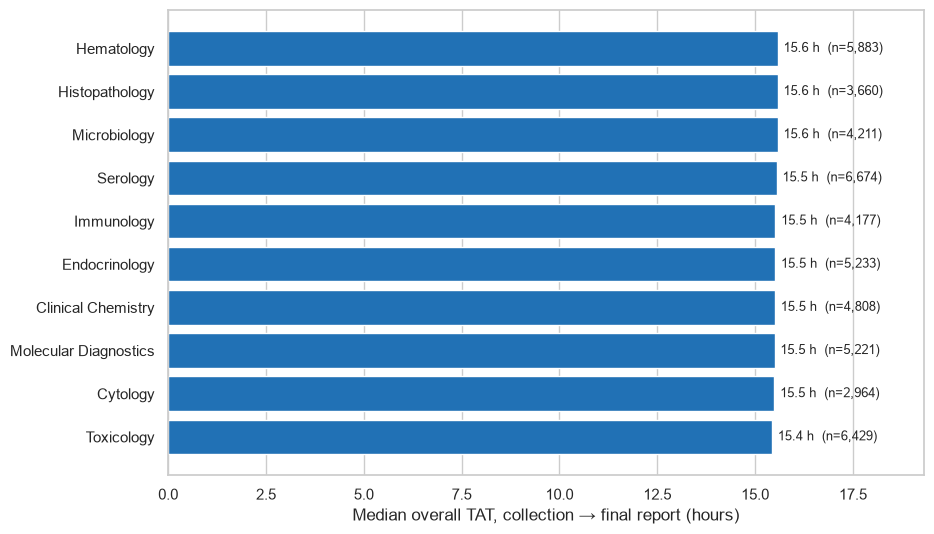

In [14]:
# Figure 1 - Overall TAT by department (requested bar chart)
ranked = dept_stage_table  # already ranked by overall_tat_h (desc)

fig, ax = plt.subplots(figsize=(9.5, 5.5))
bars = ax.barh(ranked.index, ranked["overall_tat_h"], color="#2171b5", edgecolor="white")
ax.invert_yaxis()  # slowest department on top
ax.set_xlabel("Median overall TAT, collection → final report (hours)")

for bar, dept in zip(bars, ranked.index):
    n = int(ranked.at[dept, "n_samples"])
    ax.text(bar.get_width() + 0.15, bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():.1f} h  (n={n:,})", va="center", fontsize=9)

ax.set_xlim(0, ranked["overall_tat_h"].max() * 1.24)
ax.grid(axis="y", visible=False)
save_chart("overall_tat_by_department", fig)

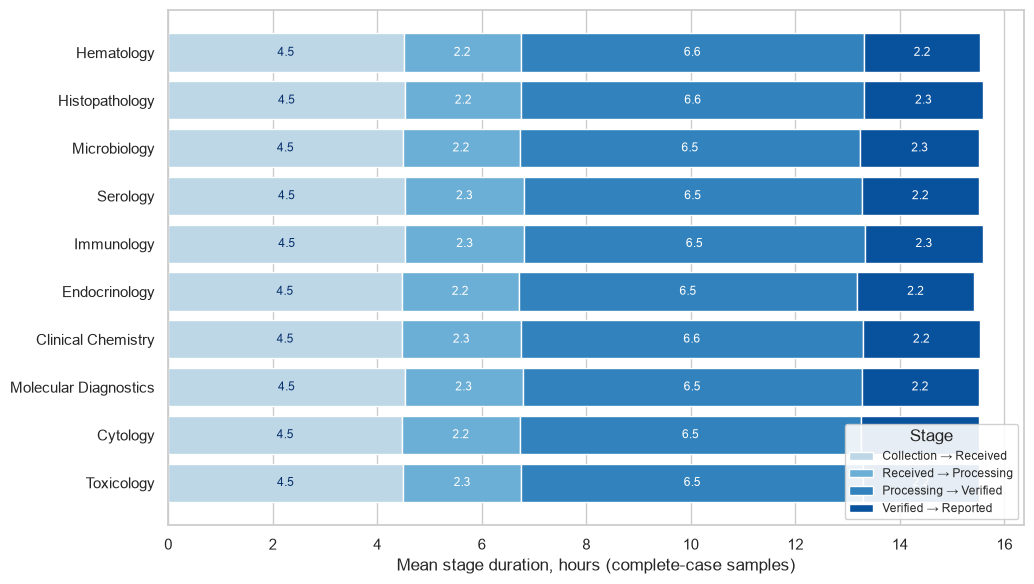

In [15]:
# Figure 2 - Stage composition by department (stacked bars, complete cases)
layer_means = (
    stage_analysis_df[stage_analysis_df[layer_cols].notna().all(axis=1)]
    .groupby("department_name")[layer_cols]
    .mean()
    .reindex(ranked.index)
)

fig, ax = plt.subplots(figsize=(10.5, 6))
left = pd.Series(0.0, index=layer_means.index)
for col, colour in zip(layer_cols, STAGE_COLORS):
    segment = layer_means[col]
    ax.barh(segment.index, segment.values, left=left, color=colour, edgecolor="white",
            label=TRANSITION_LABELS[col])
    for y, (w, start) in enumerate(zip(segment.values, left)):
        if w >= 1.5:
            ax.text(start + w / 2, y, f"{w:.1f}", ha="center", va="center", fontsize=8.5,
                    color="white" if col in (layer_cols[1], layer_cols[2], layer_cols[3]) else "#08306b")
    left = left + segment.fillna(0)

ax.invert_yaxis()  # match Figure 1 ranking
ax.set_xlabel("Mean stage duration, hours (complete-case samples)")
ax.legend(title="Stage", loc="lower right", fontsize=8.5, framealpha=0.9)
ax.grid(axis="y", visible=False)
save_chart("department_tat_stage_composition", fig)

### 9.4 Key findings

In [16]:
dept_overall = dept_stage_table["overall_tat_h"]
slowest_dept, fastest_dept = dept_overall.idxmax(), dept_overall.idxmin()

print("Overall (all departments):")
print(f"  - Main TAT contributor   : {TRANSITION_LABELS[dominant]} ({shares[dominant]:.1%} of mean overall TAT)")
print(f"  - Longest single stage   : {overall_stage_summary['median_h'].idxmax()} "
      f"({overall_stage_summary['median_h'].max():.1f} h median)")

print("\nDepartments:")
print(f"  - Longest overall TAT    : {slowest_dept} ({dept_overall[slowest_dept]:.1f} h median)")
print(f"  - Fastest overall TAT    : {fastest_dept} ({dept_overall[fastest_dept]:.1f} h median) "
      f"-> slowest is {dept_overall[slowest_dept] / dept_overall[fastest_dept]:.1f}x slower")

print("\nDominant bottleneck stage, across departments:")
display(ranked["largest_delay_stage"].value_counts().rename_axis("stage").to_frame("departments"))

Overall (all departments):
  - Main TAT contributor   : Processing → Verified (42.0% of mean overall TAT)
  - Longest single stage   : Processing → Verified (6.5 h median)

Departments:
  - Longest overall TAT    : Hematology (15.6 h median)
  - Fastest overall TAT    : Toxicology (15.4 h median) -> slowest is 1.0x slower

Dominant bottleneck stage, across departments:


,departments
stage,
Processing → Verified,10


**Takeaways of §9.** Overall TAT ranks the departments; the table names each
department's bottleneck stage; the charts show how heavily each stage weighs. One shared
ranking keeps table and charts telling the same story.

## 10. Sample processing & rejections

**Questions:** how many samples and tests are in each state? What share reaches
"reported"? What share is rejected? Which departments, tests and sample types reject the
most?

*Everything comes from tables already built in §6–§8 — no state-log or timestamp work
beyond what those sections already did.*

### 10.1 How many samples/tests in each state?

Samples are counted directly (one row per sample). A **test** counts as reaching a stage
when its sample does — a test can't move further than its sample. The chart shows the
funnel; "rejected" sits outside it, as an exit rather than a stage.

In [17]:
def build_status_funnel(sample_df: pd.DataFrame, item_df: pd.DataFrame) -> pd.DataFrame:
    """Volumes per workflow state, for samples and for the tests riding on them."""
    STAGES = ["collected", "received", "processing", "verified", "reported"]
    stages = {f"{stage}_at": stage for stage in STAGES}

    funnel = pd.DataFrame({
        "state":     ["Collected", "Received", "Processing", "Verified", "Reported", "Rejected"],
        "samples": [int(sample_df[col].notna().sum()) for col in stages]
                  + [int(sample_df["is_rejected"].sum())],
    })
    furthest = sample_df[list(stages)].notna().sum(axis=1)  # stages a sample completed
    item_states = item_df.join(furthest.rename("stages_done"), on="sample_id")
    tests_per_stage = {
        "Collected": int((item_states["stages_done"] >= 1).sum()),
        "Received": int((item_states["stages_done"] >= 2).sum()),
        "Processing": int((item_states["stages_done"] >= 3).sum()),
        "Verified": int((item_states["stages_done"] >= 4).sum()),
        "Reported": int((item_states["stages_done"] >= 5).sum()),
        "Rejected": int(item_states["is_rejected"].sum()),
    }
    funnel["tests"] = funnel["state"].map(tests_per_stage)
    return funnel.set_index("state")


status_funnel = build_status_funnel(stage_analysis_df, item_df)
status_funnel["sample_share_pct"] = status_funnel["samples"] / len(stage_analysis_df)

display(status_funnel)

n = len(stage_analysis_df)
reported = int(stage_analysis_df["reported_at"].notna().sum())
rejected = int(stage_analysis_df["is_rejected"].sum())
print("\nQ2/Q3 — headline rates (of all samples):")
print(f"  - Reach reported : {reported:,} / {n:,} = {reported / n:.1%}")
print(f"  - Rejected       : {rejected:,} / {n:,} = {rejected / n:.2%}")
print(f"  - Still in process (no reported/rejected event): {n - reported:,} ({(n - reported) / n:.1%})")

,samples,tests,sample_share_pct
state,,,
Collected,49260,72945,1.00
Received,48873,72355,0.99
Processing,48873,72355,0.99
Verified,45655,67602,0.93
Reported,42510,63036,0.86
Rejected,387,591,0.01



Q2/Q3 — headline rates (of all samples):
  - Reach reported : 42,510 / 49,260 = 86.3%
  - Rejected       : 387 / 49,260 = 0.79%
  - Still in process (no reported/rejected event): 6,750 (13.7%)


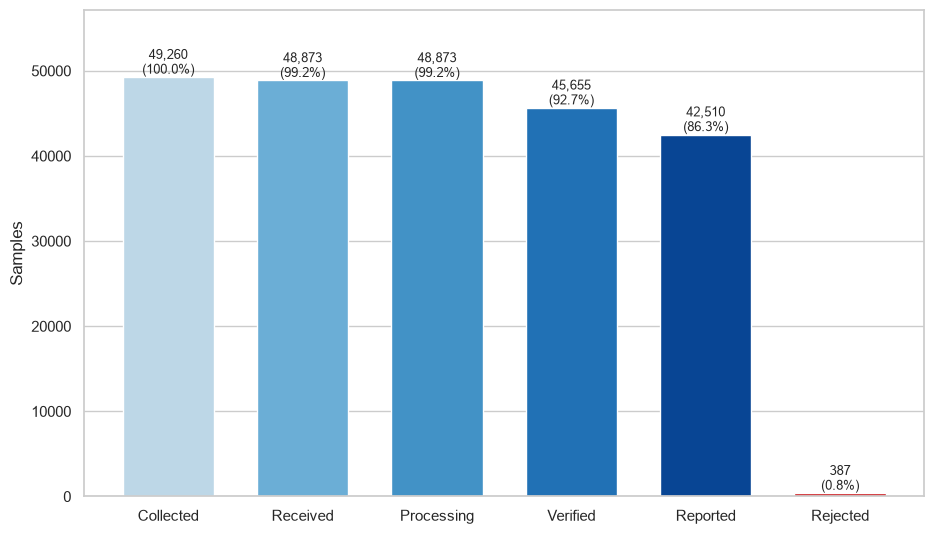

In [18]:
# Figure 4 - Volume of samples reaching each workflow state (requested bar chart)
colours = ["#bdd7e7", "#6baed6", "#4292c6", "#2171b5", "#084594", "#cb181d"]

fig, ax = plt.subplots(figsize=(9.5, 5.5))
bars = ax.bar(status_funnel.index, status_funnel["samples"], color=colours,
              edgecolor="white", width=0.68)

for bar in bars:
    share = bar.get_height() / len(stage_analysis_df)
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 400,
            f"{int(bar.get_height()):,}\n({share:.1%})", ha="center", fontsize=9.5)

ax.set_ylabel("Samples")
ax.set_ylim(0, status_funnel["samples"].max() * 1.16)
ax.grid(axis="x", visible=False)
save_chart("workflow_state_funnel", fig)

### 10.2 Who rejects the most — department, test, sample type

Each rate = rejected ÷ all **test orders**. Rejection is decided per sample: every test on
a rejected sample is rejected with it — so the three views agree with each other.

In [19]:
def rejection_table(df: pd.DataFrame, by: str, min_n: int = 1) -> pd.DataFrame:
    """Rejection rate (%) per group of `by', sorted descending, most-rejecting first."""
    out = (
        df.groupby(by)
        .agg(samples_or_tests=("order_item_id", "size"), rejections=("is_rejected", "sum"),
             rejection_rate_pct=("is_rejected", "mean"))
        .sort_values("rejection_rate_pct", ascending=False)
    )
    out["rejection_rate_pct"] = out["rejection_rate_pct"] * 100
    out["rejections"] = out["rejections"].astype(int)
    return out[out["samples_or_tests"] >= min_n]


print("Rejections by department (all 10):"); display(rejection_table(item_df, "department_name"))
print("\nTop 10 tests by rejection rate (test orders as denominator):")
display(rejection_table(item_df, "test_name").head(10))
print("\nRejections by sample type:"); display(rejection_table(item_df, "sample_type").head(6))

print("\nOverall: "
      f"{item_df['is_rejected'].sum():,} rejected test orders on "
      f"{stage_analysis_df['is_rejected'].sum():,} rejected samples "
      f"(a rejected sample takes all of its tests with it).")

Rejections by department (all 10):


,samples_or_tests,rejections,rejection_rate_pct
department_name,,,
Serology,11558,113,0.98
Immunology,7365,68,0.92
Histopathology,4350,40,0.92
Molecular Diagnostics,7292,64,0.88
Clinical Chemistry,8732,69,0.79
Toxicology,9062,71,0.78
Endocrinology,8827,68,0.77
Cytology,3360,22,0.65
Microbiology,4918,32,0.65



Top 10 tests by rejection rate (test orders as denominator):


,samples_or_tests,rejections,rejection_rate_pct
test_name,,,
Anti-HBc Total,151,6,3.97
Streptococcus agalactiae (GBS) PCR,147,5,3.40
Amikacin Peak Level,149,5,3.36
Pneumococcal Urinary Antigen,160,5,3.12
Beta-2 Glycoprotein I IgG,165,5,3.03
HSV-1 IgG,141,4,2.84
Cryptococcus neoformans PCR,142,4,2.82
VDRL (Venereal Disease Research Lab),143,4,2.80
P-ANCA (Quantitative),146,4,2.74



Rejections by sample type:


,samples_or_tests,rejections,rejection_rate_pct
sample_type,,,
semen,306,3,0.98
serum,33719,298,0.88
pleural fluid,9279,78,0.84
stool,1987,16,0.81
blood,20704,154,0.74
urine,2462,18,0.73



Overall: 591 rejected test orders on 387 rejected samples (a rejected sample takes all of its tests with it).


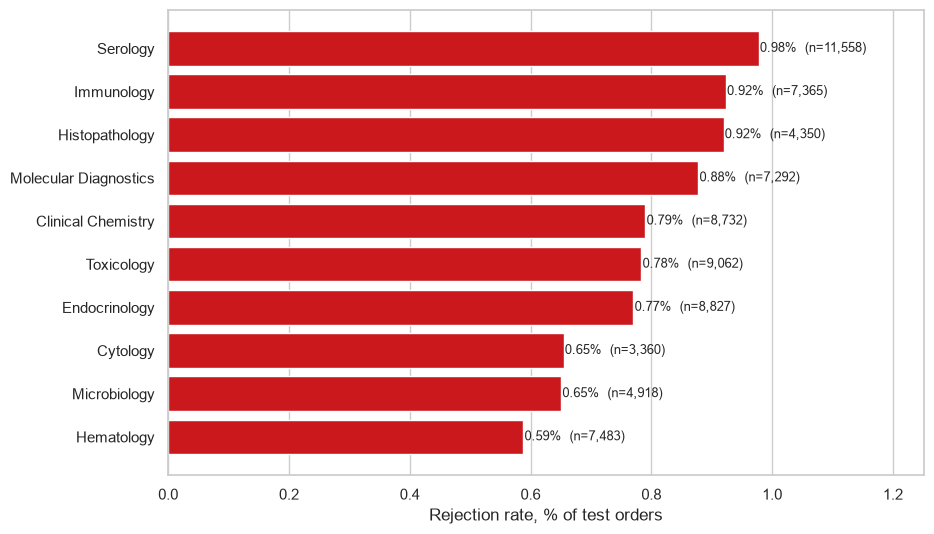

In [20]:
# Figure 5 - Rejection rate by department with volume context
rej_dept = rejection_table(item_df, "department_name")

fig, ax = plt.subplots(figsize=(9.5, 5.5))
bars = ax.barh(rej_dept.index, rej_dept["rejection_rate_pct"], color="#cb181d", edgecolor="white")
ax.invert_yaxis()

for bar, row in zip(bars, rej_dept.itertuples()):
    ax.text(bar.get_width() + 0.002, bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():.2f}%  (n={int(row.samples_or_tests):,})",
            va="center", fontsize=9)

ax.set_xlabel("Rejection rate, % of test orders")
ax.set_xlim(0, rej_dept["rejection_rate_pct"].max() * 1.28)
ax.grid(axis="y", visible=False)
save_chart("rejection_rate_by_department", fig)

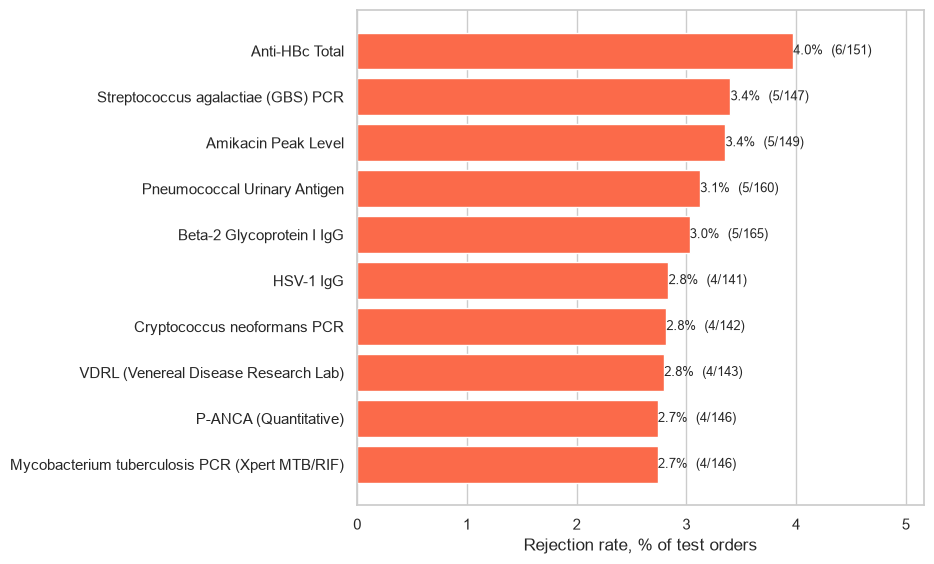

Rejection rate by sample type:


,samples_or_tests,rejections,rejection_rate_pct
sample_type,,,
semen,306,3,0.98
serum,33719,298,0.88
pleural fluid,9279,78,0.84
stool,1987,16,0.81
blood,20704,154,0.74
urine,2462,18,0.73
csf,842,6,0.71
plasma,2756,14,0.51
sputum,892,4,0.45


In [21]:
# Figure 6 - Top 10 tests by rejection rate (with volumes)
rej_test = rejection_table(item_df, "test_name").head(10)

fig, ax = plt.subplots(figsize=(9.5, 5.8))
bars = ax.barh(rej_test.index, rej_test["rejection_rate_pct"], color="#fb6a4a", edgecolor="white")
ax.invert_yaxis()

for bar, row in zip(bars, rej_test.itertuples()):
    ax.text(bar.get_width() + 0.0008, bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():.1f}%  ({int(row.rejections)}/{int(row.samples_or_tests)})",
            va="center", fontsize=9)

ax.set_xlabel("Rejection rate, % of test orders")
ax.set_xlim(0, rej_test["rejection_rate_pct"].max() * 1.3)
ax.grid(axis="y", visible=False)
save_chart("top10_tests_by_rejection_rate", fig)

rej_type = rejection_table(item_df, "sample_type")
print("Rejection rate by sample type:")
display(rej_type.round(2))

**Takeaways of §10.** The funnel shows where samples pile up or exit (§10.1), and §10.2
ranks who rejects the most across departments, tests and sample types. The lab keeps
rejections under 1% everywhere, so the fix list is short: sharpen collection practice
where the rate is highest, and target prevention at collection rather than faster
processing.

## 11. Analyzer Utilization — do we have the right number of machines?

Two plain questions about the lab's **50 analyzer models** (80 machines in service):

1. The **5 busiest** — how many machines does each have, and are more needed?
2. The **5 quietest** — how many machines does each have (is any machine nearly unused)?

| Term | Meaning |
|---|---|
| **Tests** | test orders processed |
| **Machines** | units in service (`instances_count`) |
| **Tests per machine** | Tests ÷ Machines — load falling on one unit |
| **Run time per day (min)** | minutes of running time the tests require, on average |
| **Busy % (2-shift)** | share of a 14-hour lab day the machine would be busy |

**One honest note:** `throughput_rate_per_hour` is each machine's official *maximum* speed.
Real machines stop for cleaning, QC and maintenance — so "% busy" is a best case, which
only makes the conclusions more careful, not less.

### 11.0 Every analyzer — workload, machines and spare time

In [22]:
def build_analyzer_capacity_table(df: pd.DataFrame) -> tuple[pd.DataFrame, int]:
    """One row per analyzer: workload, machine count and how busy the analyzer is.

    Busy share compares demand against a 2-shift lab day (14 hours = 840 minutes).
    """
    span_days = (df["order_created_at"].max() - df["order_created_at"].min()).days
    span_weeks = max(span_days / 7, 1)

    out = (
        df.groupby("analyzer_name")
        .agg(
            tests=("order_item_id", "size"),
            machines=("instances_count", "first"),
            tests_per_hour=("throughput_rate_per_hour", "first"),
            department_name=("department_name", "first"),
        )
        .sort_values("tests", ascending=False)
    )
    out["tests_per_machine"] = out["tests"] / out["machines"]
    out["minutes_per_day"] = out["tests"] / out["tests_per_hour"] * 60 / span_days
    out["busy_pct_2shift"] = out["minutes_per_day"] / (14 * 60) * 100
    return out, span_days


analyzer_capacity, span_days = build_analyzer_capacity_table(item_df)

friendly = analyzer_capacity[["tests", "machines", "tests_per_machine",
                              "minutes_per_day", "busy_pct_2shift", "department_name"]].rename(
    columns={"tests": "Tests", "machines": "Machines", "tests_per_machine": "Tests per machine",
             "minutes_per_day": "Run time per day (min)", "busy_pct_2shift": "Busy % (2-shift)",
             "department_name": "Department"})

print(f"The dataset covers {span_days} days (~{span_days / 30:.0f} months) and "
      f"{int(analyzer_capacity['tests'].sum()):,} test orders "
      f"on {int(analyzer_capacity['machines'].sum())} analyzer machines.")
display(friendly.round(2))

The dataset covers 365 days (~12 months) and 72,947 test orders on 80 analyzer machines.


,Tests,Machines,Tests per machine,Run time per day (min),Busy % (2-shift),Department
analyzer_name,,,,,,
DiaSorin LIAISON XL,3659,1,"3,659.00",6.68,0.80,Serology
Trinity Biotech Captia,3246,2,"1,623.00",10.67,1.27,Serology
Siemens IMMULITE 2000,3069,1,"3,069.00",6.31,0.75,Endocrinology
Agilent 6470B Triple Quad LC/MS,2670,2,"1,335.00",54.86,6.53,Toxicology
Abbott AxSYM,2502,1,"2,502.00",5.14,0.61,Serology
Shimadzu LCMS-8060,2338,1,"2,338.00",38.43,4.58,Toxicology
Beckman Coulter DXI 800,2240,2,"1,120.00",4.33,0.52,Endocrinology
Bio-Rad Bio-Plex 2200,2151,2,"1,075.50",5.89,0.70,Serology
Thermo Scientific Q Exactive,2145,1,"2,145.00",35.26,4.20,Toxicology


### 11.1 The 5 busiest analyzers — is the machine count right?

Top 5 by test volume. The chart shows tests and **machines in service**; the table adds
busy minutes per day — the input to the *buy more machines?* decision, answered in the
verdict column.

In [23]:
def capacity_verdict(busy_pct: float) -> str:
    """Is it time to buy another machine for this analyzer?"""
    if busy_pct >= 60:
        return "MORE MACHINES NEEDED"
    if busy_pct >= 20:
        return "Getting busy - keep an eye"
    return "Plenty of spare time"


top5 = analyzer_capacity.head(5).copy()
top5["Do we need more machines?"] = top5["busy_pct_2shift"].map(capacity_verdict)
display(top5[["tests", "machines", "tests_per_machine",
              "minutes_per_day", "busy_pct_2shift", "Do we need more machines?"]].round(2))

print("In plain terms:")
for name, row in top5.iterrows():
    print(f"  - {name}: {int(row['tests']):,} tests in {span_days} days "
          f"(~{row['tests'] / span_days:.0f} a day) on {int(row['machines'])} "
          f"machine{'s' if row['machines'] > 1 else ''} "
          f"-> only {row['minutes_per_day']:.0f} minutes of run time a day")

busiest = top5["minutes_per_day"].max()
print(f"\nBottom line: the busiest analyzer in the lab needs only {busiest:.0f} minutes "
      f"of run time per day. Today's workload does not require buying more machines.")

,tests,machines,tests_per_machine,minutes_per_day,busy_pct_2shift,Do we need more machines?
analyzer_name,,,,,,
DiaSorin LIAISON XL,3659,1,"3,659.00",6.68,0.80,Plenty of spare time
Trinity Biotech Captia,3246,2,"1,623.00",10.67,1.27,Plenty of spare time
Siemens IMMULITE 2000,3069,1,"3,069.00",6.31,0.75,Plenty of spare time
Agilent 6470B Triple Quad LC/MS,2670,2,"1,335.00",54.86,6.53,Plenty of spare time
Abbott AxSYM,2502,1,"2,502.00",5.14,0.61,Plenty of spare time


In plain terms:
  - DiaSorin LIAISON XL: 3,659 tests in 365 days (~10 a day) on 1 machine -> only 7 minutes of run time a day
  - Trinity Biotech Captia: 3,246 tests in 365 days (~9 a day) on 2 machines -> only 11 minutes of run time a day
  - Siemens IMMULITE 2000: 3,069 tests in 365 days (~8 a day) on 1 machine -> only 6 minutes of run time a day
  - Agilent 6470B Triple Quad LC/MS: 2,670 tests in 365 days (~7 a day) on 2 machines -> only 55 minutes of run time a day
  - Abbott AxSYM: 2,502 tests in 365 days (~7 a day) on 1 machine -> only 5 minutes of run time a day

Bottom line: the busiest analyzer in the lab needs only 55 minutes of run time per day. Today's workload does not require buying more machines.


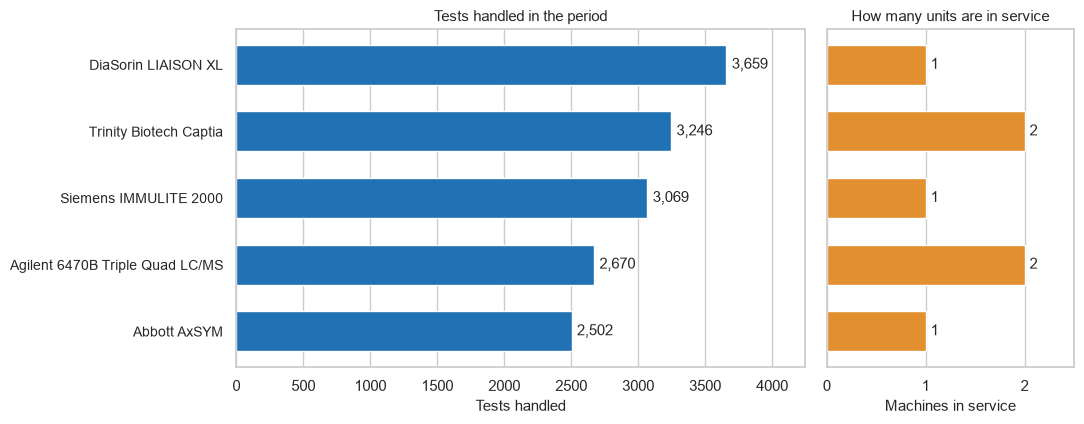

In [24]:
# Figure 8 - The 5 busiest analyzers: tests vs machines (two simple panels)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4),
                         gridspec_kw={"width_ratios": [2.3, 1.0]}, sharey=False)
names = list(top5.index)
y_pos = range(len(names))

axes[0].barh(y_pos, top5["tests"], color="#2171b5", height=0.6)
for i, (name, _) in enumerate(zip(names, y_pos)):
    axes[0].text(top5.loc[name, "tests"] + 40, i, f"{int(top5.loc[name, 'tests']):,}",
                 va="center", fontsize=10.5)
axes[0].set_xlabel("Tests handled", fontsize=11)
axes[0].set_title("Tests handled in the period", fontsize=11)
axes[0].set_xlim(0, top5["tests"].max() * 1.16)

axes[1].barh(y_pos, top5["machines"], color="#e28f2f", height=0.6)
for i, (name, _) in enumerate(zip(names, y_pos)):
    axes[1].text(top5.loc[name, "machines"] + 0.05, i, f"{int(top5.loc[name, 'machines'])}",
                 va="center", fontsize=10.5)
axes[1].set_xlabel("Machines in service", fontsize=11)
axes[1].set_title("How many units are in service", fontsize=11)
axes[1].set_xlim(0, top5["machines"].max() * 1.25)
axes[1].set_xticks(range(0, int(top5['machines'].max()) + 1))

for ax_ in axes:
    ax_.set_yticks(list(y_pos))
    ax_.set_yticklabels([] if ax_ is axes[1] else names, fontsize=10)
    ax_.invert_yaxis()
    ax_.grid(axis="y", visible=False)

save_chart("top5_analyzers_by_workload", fig)

### 11.2 The 5 quietest analyzers — spare capacity

Bottom 5 by test volume, with machine counts. Many machines + few tests a day = a machine
sitting nearly unused all day — spare room to absorb extra work, or a case for fewer units.

In [25]:
bottom5 = analyzer_capacity.tail(5).copy()

# Would ONE machine be enough to do this whole workload?
bottom5["minutes_per_day_if_1_machine"] = bottom5["tests"] / bottom5["tests_per_hour"] * 60 / span_days
one_machine_enough = bottom5["minutes_per_day_if_1_machine"] < 60  # < 1 hour a day

bottom5["1 machine would be enough?"] = [
    ("Yes" if enough else "No")
    + (f" - busy only {mins:.0f} min/day" if enough else "")
    for enough, mins in zip(one_machine_enough, bottom5["minutes_per_day_if_1_machine"])
]
display(bottom5[["tests", "machines", "tests_per_machine", "minutes_per_day",
                 "busy_pct_2shift", "1 machine would be enough?", "department_name"]].round(2))

print("In plain terms:")
for name, row in bottom5.iterrows():
    print(f"  - {name}: {int(row['tests']):,} tests in {span_days} days "
          f"(~{row['tests'] / span_days:.1f} a day) on {int(row['machines'])} "
          f"machine{'s' if row['machines'] > 1 else ''}; the whole workload "
          f"fits in {row['minutes_per_day_if_1_machine']:.0f} min/day")

,tests,machines,tests_per_machine,minutes_per_day,busy_pct_2shift,1 machine would be enough?,department_name
analyzer_name,,,,,,,
BACTEC FX40,726,3,242.00,2.98,0.36,Yes - busy only 3 min/day,Microbiology
BioMerieux BacT/ALERT 3D,700,1,700.00,2.30,0.27,Yes - busy only 2 min/day,Microbiology
Roche Cobas e411,430,2,215.00,0.80,0.10,Yes - busy only 1 min/day,Immunology
Ventana BenchMark ULTRA,427,1,427.00,4.68,0.56,Yes - busy only 5 min/day,Histopathology
Abbott CELL-DYN Ruby,426,1,426.00,0.93,0.11,Yes - busy only 1 min/day,Hematology


In plain terms:
  - BACTEC FX40: 726 tests in 365 days (~2.0 a day) on 3 machines; the whole workload fits in 3 min/day
  - BioMerieux BacT/ALERT 3D: 700 tests in 365 days (~1.9 a day) on 1 machine; the whole workload fits in 2 min/day
  - Roche Cobas e411: 430 tests in 365 days (~1.2 a day) on 2 machines; the whole workload fits in 1 min/day
  - Ventana BenchMark ULTRA: 427 tests in 365 days (~1.2 a day) on 1 machine; the whole workload fits in 5 min/day
  - Abbott CELL-DYN Ruby: 426 tests in 365 days (~1.2 a day) on 1 machine; the whole workload fits in 1 min/day


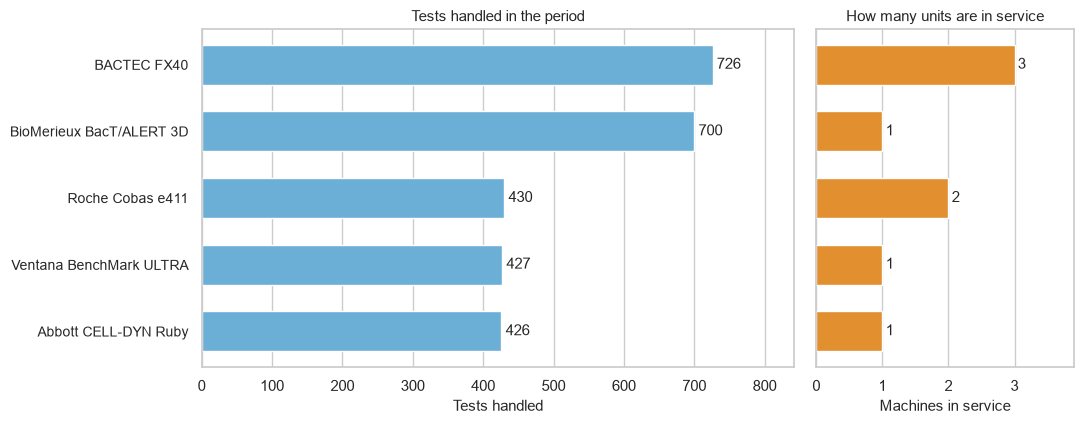

In [26]:
# Figure 9 - The 5 quietest analyzers: tests vs machines (two simple panels)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4),
                         gridspec_kw={"width_ratios": [2.3, 1.0]}, sharey=False)
names = list(bottom5.index)
y_pos = range(len(names))

axes[0].barh(y_pos, bottom5["tests"], color="#6baed6", height=0.6)
for i, name in enumerate(names):
    axes[0].text(bottom5.loc[name, "tests"] + 6, i, f"{int(bottom5.loc[name, 'tests']):,}",
                 va="center", fontsize=10.5)
axes[0].set_xlabel("Tests handled", fontsize=11)
axes[0].set_title("Tests handled in the period", fontsize=11)
axes[0].set_xlim(0, bottom5["tests"].max() * 1.16)

axes[1].barh(y_pos, bottom5["machines"], color="#e28f2f", height=0.6)
for i, name in enumerate(names):
    axes[1].text(bottom5.loc[name, "machines"] + 0.05, i, f"{int(bottom5.loc[name, 'machines'])}",
                 va="center", fontsize=10.5)
axes[1].set_xlabel("Machines in service", fontsize=11)
axes[1].set_title("How many units are in service", fontsize=11)
axes[1].set_xlim(0, bottom5["machines"].max() * 1.3)
axes[1].set_xticks(range(0, int(bottom5['machines'].max()) + 1))

for ax_ in axes:
    ax_.set_yticks(list(y_pos))
    ax_.set_yticklabels([] if ax_ is axes[1] else names, fontsize=10)
    ax_.invert_yaxis()
    ax_.grid(axis="y", visible=False)

save_chart("bottom5_analyzers_by_workload", fig)

**Bottom line (§11), in plain words**

- **No analyzer is overloaded.** Even the busiest (DiaSorin LIAISON XL — 3,659 tests in the
  year) needs only **~7 minutes of run time a day**; the most demanding (Agilent LC-MS)
  stays under an hour a day.
- **More machines are not needed for today's workload.** The real risk: the three busiest
  analyzers each run on a **single machine** — one breakdown stops a lot of work at once,
  so maintenance discipline is what protects them.
- **Some machines are nearly idle.** One analyzer keeps **3 machines** for ~5 tests a day;
  a single machine could do the whole job. That is spare capacity — use it for re-runs and
  training, or review the fleet.

## 12. Operational report PDF — one page per chart

Assembles every chart of this notebook into **`reports/operational_analysis.pdf`** —
the same one-page pattern as the demand report: chart heading → short introduction →
chart image → key insights → potential bottleneck → suggested action.

Chart images are exported into `laboratory_operational_analysis_summary/` (300 dpi PNGs)
and the layout helpers come from the shared `pdf_functions` module, so both reports keep
an identical look.

In [27]:
from laboratory_data_analysis.pdf_functions import ReportPDF, add_text, add_chart_section

REPORT_CHARTS = [
    {
        "title": "Overall TAT by Department",
        "intro": "Median end-to-end turnaround time (collection to final report) for each "
                 "of the 10 departments, ranked from slowest to fastest.",
        "chart": "overall_tat_by_department",
        "insights": [
            "All 10 departments sit within 15.4 to 15.6 median hours - a spread of only "
            "about 9 minutes.",
            "Hematology is the slowest department (15.58 h); Toxicology the fastest "
            "(15.43 h).",
            "No department is an outlier - the delay is shared by the whole laboratory.",
        ],
        "bottleneck": "None at department level: slow turnaround is a laboratory-wide "
                      "process property, not one department's problem.",
        "action": "Do not chase individual departments. Target the slow workflow stage "
                  "process-wide (see the stage-composition chart on the next page).",
    },
    {
        "title": "Department TAT Composition by Workflow Stage",
        "intro": "How each department's overall TAT splits across the four workflow "
                 "stages; the thickest segment is that department's dominant delay.",
        "chart": "department_tat_stage_composition",
        "insights": [
            "Processing -> Verified is the largest segment in every department: about "
            "6.5 h, 42% of mean TAT.",
            "Collection -> Received adds about 4.5 h (29%); the other two stages are "
            "minor at roughly 2.2-2.3 h (14-16%).",
            "The composition is almost identical across all departments.",
        ],
        "bottleneck": "The processing/verification bench (Processing -> Verified) is the "
                      "single heaviest stage laboratory-wide.",
        "action": "Concentrate improvement on this stage: coverage at verified-time, "
                  "automation of checks, and review of queuing before verification.",
    },
    {
        "title": "Samples Reaching Each Workflow State",
        "intro": "How many samples progress through collected, received, processing, "
                 "verified and reported - and how many exit as rejected.",
        "chart": "workflow_state_funnel",
        "insights": [
            "49,260 samples were collected; 42,510 (86.3%) reached a final report.",
            "387 samples (0.79%) rejected before processing started.",
            "6,750 samples (13.7%) were neither reported nor rejected - open work at the "
            "data snapshot.",
        ],
        "bottleneck": "Attrition concentrates after processing: roughly 6.2k samples sit "
                      "between verified and reported, plus the rejections.",
        "action": "Review the unfinished backlog weekly and chase its oldest samples; "
                  "keep the reported share moving towards 100%.",
    },
    {
        "title": "Rejection Rate by Department",
        "intro": "Rejections as a share of test orders per department - the "
                 "department view of collection quality.",
        "chart": "rejection_rate_by_department",
        "insights": [
            "Serology records the highest rate at 0.98% (113 of 11,558 orders); "
            "Immunology and Histopathology follow at 0.92%.",
            "Hematology is the cleanest at 0.59%.",
            "Every department keeps rejections below 1% of its test orders.",
        ],
        "bottleneck": "Serology also carries the largest order volume, so its marginally "
                      "higher rate is also the biggest absolute contributor.",
        "action": "Reinforce collection practice (vial type, tube fill, labelling) in "
                  "Serology, Immunology and Histopathology; track the rate weekly.",
    },
    {
        "title": "Top 10 Tests by Rejection Rate",
        "intro": "The ten tests with the highest share of rejected orders - the "
                 "test-level view of rejection risk.",
        "chart": "top10_tests_by_rejection_rate",
        "insights": [
            "Anti-HBc Total tops the list at about 4% (6 of 151 orders).",
            "GBS PCR and Amikacin Peak Level follow at about 3.4% each.",
            "The list is long-tailed: most tests reject far below these levels.",
        ],
        "bottleneck": "Small order counts: one or two extra rejections visibly moves "
                      "these rates.",
        "action": "Check the collection protocol (sample requirements, tube handling) for "
                  "the top three tests; keep the rest of the list on routine watch.",
    },
    {
        "title": "Top 5 Analyzers by Workload",
        "intro": "The five busiest analyzers by test orders, side by side with the number "
                 "of units in service.",
        "chart": "top5_analyzers_by_workload",
        "insights": [
            "DiaSorin LIAISON XL carries the most tests (3,659) - on a single machine; "
            "Siemens IMMULITE 2000 (3,069) and Abbott AxSYM (2,502) are also "
            "single-unit.",
            "Even the busiest needs well under one hour of rated run time per day.",
            "No top-5 analyzer needs more machines for today's volume.",
        ],
        "bottleneck": "Single-unit dependence on the three heaviest analyzers - one "
                      "breakdown stops roughly 26-28 tests a day each.",
        "action": "Protect the single-unit heavy hitters with preventive maintenance and "
                  "a documented backup routing plan.",
    },
    {
        "title": "Bottom 5 Analyzers by Workload",
        "intro": "The five quietest analyzers by test orders, with their machine counts - "
                 "where the spare capacity sits.",
        "chart": "bottom5_analyzers_by_workload",
        "insights": [
            "BACTEC FX40 keeps 3 machines for 726 tests (~5 a day) - one machine would "
            "cover it in about 3 minutes a day.",
            "Roche Cobas e411 runs 430 tests across 2 machines (about 1 busy minute a "
            "day).",
            "These machines are effectively idle relative to their rated speed.",
        ],
        "bottleneck": "None - this end of the scale is spare capacity, not pressure.",
        "action": "Point idle machines at QC runs, re-runs and training workload; review "
                  "multi-unit fleets (e.g. BACTEC FX40) for consolidation.",
    },
]

pdf = ReportPDF()
pdf.add_page()

for entry in REPORT_CHARTS:
    add_text(pdf, entry["title"], bold=True, spacing_after=5)
    add_text(pdf, entry["intro"], spacing_after=5)
    add_chart_section(pdf, f"../laboratory_operational_analysis_summary/{entry['chart']}.png")
    add_text(pdf, "Key insights", bold=True, spacing_after=5)
    add_text(pdf, "\n".join(f"- {bullet}" for bullet in entry["insights"]), spacing_after=5)
    add_text(pdf, "Potential bottleneck", bold=True, spacing_after=5)
    add_text(pdf, entry["bottleneck"], spacing_after=5)
    add_text(pdf, "Suggested action", bold=True, spacing_after=5)
    add_text(pdf, entry["action"], spacing_after=5)
    if entry is not REPORT_CHARTS[-1]:
        pdf.add_page()

pdf.output("../reports/operational_analysis.pdf")
print(f"PDF written: ../reports/operational_analysis.pdf "
      f"({len(REPORT_CHARTS)} chart pages)")

PDF written: ../reports/operational_analysis.pdf (7 chart pages)


## Notes and next steps

- **Definitions:** overall TAT = collection → final report; stage TATs = the pre-analytical,
  analytical and post-analytical intervals. All in **hours**, timestamps in **UTC**.
- **Scope:** one row per **sample**; join `tat_analysis_df` to the item/report datasets for
  test- or parameter-level views.
- **Data hygiene:** source files untouched — dates were fixed in memory only.
- **Report PDF (§12):** one page per chart -> `reports/operational_analysis.pdf`
  (images in `laboratory_operational_analysis_summary/`).
- **Next steps:** TAT trends by department and test; SLA-breach drivers; weekend vs
  weekday; hour-of-day congestion.
- **Analyzer capacity (§11):** busiest and quietest analyzers with their machine counts —
  pairs with §10's rejection profile when weighing redundancy or consolidation.